# Which patterns are real, and which are settings of the data?

**Question:** the team's main findings rest on a few very regular patterns: Garden's unit costs about 1.43x Harbour's, Tuesday about 1.6x other days, steady growth at every branch. Are these the kind of patterns real shops produce, or do they look like **fixed settings plus random noise**, the way a simulator or a formula-based accounting rule would produce them?

**Why it matters:** a fixed setting cannot be fixed by negotiating with a supplier or copying a Tuesday promotion. If the patterns are settings, the right next step for several findings is the same single question to Stories: *how was this file produced, and how are standard costs calculated?*

No test here can prove the data was generated. Each test asks whether a pattern is **more regular than real business data normally is**, and compares it with two references: the Maven Roasters dataset (3 New York shops, also fictional but built differently) and Google Maps popular times for 10 real Stories shops in Lebanon (see `reports/tuesday_external/`).

Throughout, **observed facts** are kept separate from **interpretation**.

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.stats import chi2_contingency, chi2

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
# Repository layout: run from the repo root or notebooks/; data comes from STORIES_DATA or data/
ROOT = Path.cwd()
if not (ROOT / "reports").exists(): ROOT = ROOT.parent
DATA = Path(os.environ.get("STORIES_DATA", ROOT / "data" / "stories_transactions.csv"))
MAVEN = Path(os.environ.get("MAVEN_DATA", ROOT / "data" / "Coffee Shop Sales.xlsx"))
FIG = ROOT / "figures" / "data_fingerprints"; FIG.mkdir(parents=True, exist_ok=True)

BRANCH_COLORS = {"Harbour": "#2a78d6", "Garden": "#eb6834", "Uptown": "#1baf7a"}
BRANCHES = list(BRANCH_COLORS)
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titleweight": "bold", "axes.titlesize": 11, "axes.titlelocation": "left",
    "font.size": 9, "legend.frameon": False, "lines.linewidth": 2,
})
def save(fig, name):
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight", dpi=150)

## 1. Load the data

Same cleaning as `01_eda.ipynb` (132 exact duplicate rows removed). The Maven file is optional: download it from [Maven Analytics](https://mavenanalytics.io/data-playground/coffee-shop-sales) into `data/` or set `MAVEN_DATA`; the Maven comparisons are skipped if it is missing.

In [2]:
raw = pd.read_csv(DATA, dtype={"Customer ID": "string"})
raw = raw.rename(columns={
    "Transaction ID": "txn", "Date": "date", "Time": "time", "Branch": "branch",
    "Customer ID": "cust", "Order Type": "order_type", "Product": "product",
    "Category": "category", "Quantity": "qty", "Unit Price (USD)": "price",
    "Discount Rate": "disc", "Unit Cost (USD)": "cost",
    "Line Revenue (USD)": "rev", "Line Gross Profit (USD)": "gp"})
raw = raw[~raw.duplicated()].copy()
raw["ts"] = pd.to_datetime(raw["date"] + " " + raw["time"])
raw["date"] = pd.to_datetime(raw["date"])
raw["hour"] = raw.ts.dt.hour
txn = raw.groupby("txn").agg(branch=("branch", "first"), date=("date", "first"), hour=("hour", "first"),
                             lines=("product", "size"), cust=("cust", "first"))
print("line items:", len(raw), "| transactions:", len(txn))

HAVE_MAVEN = MAVEN.exists()
if HAVE_MAVEN:
    mv = pd.read_excel(MAVEN)
    mv["date"] = pd.to_datetime(mv.transaction_date)
    mv["hour"] = mv.transaction_time.astype(str).str[:2].astype(int)
    print("Maven rows:", len(mv), "| stores:", sorted(mv.store_location.unique()))
else:
    print("Maven file not found; Maven comparisons will be skipped.")

line items: 51045 | transactions: 33887


Maven rows: 149116 | stores: ['Astoria', "Hell's Kitchen", 'Lower Manhattan']


## 2. Are branch prices and costs a formula?

If Garden's costs were higher because of a different supplier, recipes or waste, the gap would differ by product: beans, milk, pastries and bottled water do not all get 43% dearer together. A **formula** (a standard-cost rule, or a simulator setting) would instead give the same multiplier on every product, up to rounding to the cent.

**Test:** is there a single number `k` such that `round(Harbour value x k, 2)` reproduces the other branch's value for **all 45 products**?

In [3]:
pc = raw.groupby(["product", "branch"])[["price", "cost"]].first().unstack()

def exact_multiplier(base, other):
    # range of k for which round(base * k, 2) == other on every product
    lo = ((other - 0.005) / base).max(); hi = ((other + 0.005) / base).min()
    best = max(((k, int((np.round(base * k + 1e-9, 2) == other).sum())) for k in np.arange(0.85, 1.5, 0.0001)), key=lambda x: x[1])
    return lo, hi, best

rows = []
for col in ["cost", "price"]:
    pairs = [("Harbour", "Garden"), ("Harbour", "Uptown")] + ([("Garden", "Uptown")] if col == "price" else [])
    for base_br, br in pairs:
        lo, hi, (k, n) = exact_multiplier(pc[(col, base_br)].values, pc[(col, br)].values)
        rows.append(dict(column=col, branch=br, relative_to=base_br, k_low=lo, k_high=hi,
                         best_k=k, products_matched=n, ratio_sd=(pc[(col, br)] / pc[(col, base_br)]).std()))
mult = pd.DataFrame(rows)
mult.round(5)

,column,branch,relative_to,k_low,k_high,best_k,products_matched,ratio_sd
0,cost,Garden,Harbour,1.42994,1.43019,1.4300,45,0.00195
1,cost,Uptown,Harbour,0.95992,0.96014,0.9600,45,0.00269
2,price,Garden,Harbour,0.95218,0.95261,0.9522,45,0.00050
3,price,Uptown,Harbour,0.91460,0.91390,0.9140,37,0.00078
4,price,Uptown,Garden,0.95989,0.96009,0.9599,45,0.00061


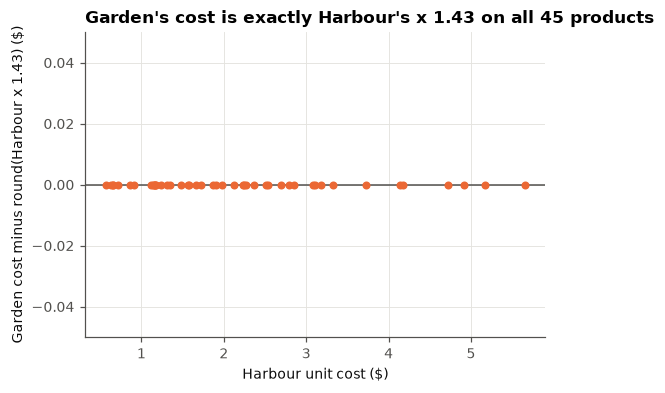

In [4]:
fig, ax = plt.subplots(figsize=(5.4, 3.6))
h, g = pc[("cost", "Harbour")], pc[("cost", "Garden")]
ax.scatter(h, g - np.round(h * 1.43 + 1e-9, 2), color="#eb6834", s=18, zorder=3)
ax.axhline(0, color=MUTED, lw=1)
ax.set_ylim(-0.05, 0.05)
ax.set_xlabel("Harbour unit cost ($)"); ax.set_ylabel("Garden cost minus round(Harbour x 1.43) ($)")
ax.set_title("Garden's cost is exactly Harbour's x 1.43 on all 45 products")
save(fig, "11_garden_cost_formula"); plt.show()

**Observed:**
- Garden's unit cost = `round(Harbour cost x 1.43, 2)` on **45 of 45** products. Uptown's = `round(Harbour cost x 0.96, 2)` on 45 of 45.
- Garden's price = `round(Harbour price x 0.9524, 2)` (that is, Harbour's price divided by 1.05) on 45 of 45.
- Uptown's price does not fit one multiplier of Harbour's, but it equals `round(Garden price x 0.96, 2)` on 45 of 45. So Uptown's prices are derived from Garden's.

**Interpretation:** every branch price and cost is a fixed multiple of another branch's, to the cent. Real supplier, recipe or waste differences cannot produce this. What can: a **standard-cost allocation formula** (for example, "Garden standard cost = base cost x 1.43"), a **zone-pricing rule** (common in real chains), or a **simulator setting**. All three mean the same thing for the $15,923 Garden cost gap in the root-cause report: it is a formula, so it will not be recovered by negotiating ingredient by ingredient. Finance needs to say which formula it is and whether any part of the 43% is avoidable cash.

### 2.1 A multiplier, or a fixed extra amount per item?

A different kind of rule would add the same dollar amount to every item, such as a delivery or handling fee per unit. If that were the mechanism, `Garden cost = Harbour cost + c` would fit as well as the multiplier. Both rules are fitted to the 45 products and compared by average error.

In [5]:
h, g = pc[("cost", "Harbour")], pc[("cost", "Garden")]
c = (g - h).mean()
fits = pd.DataFrame({
    "rule": ["Garden = Harbour x 1.43 (rounded to the cent)", f"Garden = Harbour + ${c:.2f}"],
    "average error ($)": [(g - np.round(h * 1.43 + 1e-9, 2)).abs().mean(), (g - (h + c)).abs().mean()],
    "largest error ($)": [(g - np.round(h * 1.43 + 1e-9, 2)).abs().max(), (g - (h + c)).abs().max()]})
fits.round(4)

,rule,average error ($),largest error ($)
0,Garden = Harbour x 1.43 (rounded to the cent),0.00,0.0000
1,Garden = Harbour + $0.95,0.45,1.4802


**Observed:** the multiplier reproduces every product to the cent, while a fixed extra amount per item misses by about 45 cents on average. So the gap scales with each item's cost; it is not a flat fee.

### 2.2 Are some categories worse than others?

In dollars, Garden's gap is largest on meals and sandwiches. That could look like a problem with food suppliers. The check is whether the *ratio* also differs by category, or only the dollar amount.

In [6]:
prod_cost = pd.DataFrame({"category": raw.groupby("product").category.first(), "harbour": h, "garden": g})
prod_cost["gap"] = prod_cost.garden - prod_cost.harbour
prod_cost["ratio"] = prod_cost.garden / prod_cost.harbour
prod_cost["residual"] = prod_cost.garden - np.round(prod_cost.harbour * 1.43 + 1e-9, 2)
(prod_cost.groupby("category")
 .agg(products=("gap", "size"), mean_harbour_cost=("harbour", "mean"), mean_dollar_gap=("gap", "mean"),
      mean_ratio=("ratio", "mean"), mean_residual=("residual", "mean"))
 .sort_values("mean_dollar_gap", ascending=False).round(4))

,products,mean_harbour_cost,mean_dollar_gap,mean_ratio,mean_residual
category,,,,,
Meals,3,4.4533,1.9167,1.4304,0.0
Sandwiches,4,4.4400,1.9075,1.4296,0.0
Breakfast,3,3.5367,1.5233,1.4307,0.0
Desserts,4,2.7475,1.1825,1.4304,0.0
Matcha & Tea,6,1.7733,0.7650,1.4321,0.0
Cold Coffee,5,1.6880,0.7260,1.4301,0.0
Bakery,8,1.4800,0.6362,1.4299,0.0
Hot Coffee,7,1.3286,0.5700,1.4292,0.0
Cold Drinks,5,1.2880,0.5520,1.4286,0.0


**Observed:** meals and sandwiches have the largest dollar gaps only because they cost more to begin with. Every category's ratio is 1.43, and no category deviates from the rule. There is no category-specific cost problem to investigate.

## 3. Do daily sales vary as much as real sales do?

Real daily transactions move with weather, local events, staff and stock-outs, so they vary **more** than pure chance. A simulator that draws each day from fixed rates produces variation **equal to pure chance**.

**Test:** model each branch-day as `level of that branch-week x fixed weekday factor for that branch`, then measure how much the counts scatter around it. The **dispersion** is 1.0 for pure chance (Poisson) and above 1 when real-world shocks are present. Full weeks only.

In [7]:
def dispersion(day):
    # day: store, date, n. Fit n ~ level(store, week) x factor(store, weekday) and return Pearson dispersion
    d = day.copy()
    d["wk"], d["dow"] = d.date.dt.to_period("W"), d.date.dt.dayofweek
    d = d[d.groupby(["store", "wk"]).dow.transform("count") == 7].copy()
    d["l"], d["f"] = d.groupby(["store", "wk"]).n.transform("mean"), 1.0
    for _ in range(100):
        d["f"] = d.groupby(["store", "dow"]).n.transform("sum") / d.groupby(["store", "dow"]).l.transform("sum")
        d["l"] = d.groupby(["store", "wk"]).n.transform("sum") / d.groupby(["store", "wk"]).f.transform("sum")
    e = d.l * d.f
    n_params = d.groupby(["store", "wk"]).ngroups + d.store.nunique() * 6
    return ((d.n - e) ** 2 / e).sum() / (len(d) - n_params), len(d)

stories_day = txn.groupby(["branch", "date"]).size().rename("n").reset_index().rename(columns={"branch": "store"})
disp = {"Stories": dispersion(stories_day)}
if HAVE_MAVEN:
    maven_day = mv.groupby(["store_location", "date"]).size().rename("n").reset_index().rename(columns={"store_location": "store"})
    disp["Maven"] = dispersion(maven_day)
disp = pd.DataFrame(disp, index=["dispersion (1 = pure chance)", "branch-days"]).T
disp.round(3)

,dispersion (1 = pure chance),branch-days
Stories,0.994,525.0
Maven,4.484,525.0


**Observed:** Stories' daily counts scatter almost exactly as much as pure chance predicts. Maven, another fictional dataset built differently, scatters about four times as much.

**Interpretation:** once the weekly level and a fixed weekday factor are known, there is nothing left in the Stories days: no rainy days, no events, no stock-outs. That is what drawing each day from fixed rates looks like. It is possible in a very stable real business, but it would be unusual.

## 4. Is the weekly and daily rhythm identical everywhere?

Different shops have different rhythms (a mall store, a campus store, a seaside store). The real Stories shops in Google Maps do. A single simulator weekday setting applied to every branch would give **the same rhythm at every branch**.

In [8]:
def weekday_index(day):
    d = day.assign(dow=day.date.dt.dayofweek).groupby(["store", "dow"]).n.mean().unstack()
    return d.div(d.mean(axis=1), axis=0)

idx = {"Stories": weekday_index(stories_day)}
if HAVE_MAVEN:
    idx["Maven"] = weekday_index(maven_day)

# Real Stories shops: Google Maps popular times, hours shown on every day, full-week branches only
g = pd.read_csv(ROOT / "reports" / "tuesday_external" / "google_popular_times.csv").dropna(subset=["busyness"])
g = g[g.day.isin(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])]
full = g.groupby("branch").day.nunique() == 7
g = g[g.branch.isin(full[full].index)]
common = g.groupby(["branch", "hour"]).day.nunique().reset_index().query("day == 7")[["branch", "hour"]]
g = g.merge(common, on=["branch", "hour"])
gi = g.groupby(["branch", "day"]).busyness.mean().unstack()[["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]]
gi.columns = range(7)
idx["Real Stories shops (Google Maps)"] = gi.div(gi.mean(axis=1), axis=0)

spread = pd.Series({k: v.std().mean() for k, v in idx.items()}, name="average spread between branches (SD of weekday index)")
print(spread.round(3).to_string())
idx["Stories"].round(3)

Stories                             0.013
Maven                               0.021
Real Stories shops (Google Maps)    0.145


dow,0,1,2,3,4,5,6
store,,,,,,,
Garden,0.968,1.535,0.981,0.951,1.045,0.692,0.829
Harbour,0.938,1.515,1.011,0.957,1.063,0.682,0.833
Uptown,0.952,1.506,0.976,0.989,1.050,0.693,0.834


In [9]:
hour_tab = txn.groupby(["branch", "hour"]).size().unstack()
print("Stories: hourly shape differs by branch?  p =", round(chi2_contingency(hour_tab.values)[1], 3))
dow_hour = txn.assign(dow=txn.date.dt.dayofweek).groupby(["dow", "hour"]).size().unstack()
print("Stories: hourly shape differs by weekday? p =", round(chi2_contingency(dow_hour.values)[1], 3))
if HAVE_MAVEN:
    mh = mv.groupby(["store_location", "hour"]).size().unstack().fillna(0)
    print("Maven:   hourly shape differs by store?   p =", chi2_contingency(mh.values)[1])

Stories: hourly shape differs by branch?  p = 0.916
Stories: hourly shape differs by weekday? p = 0.568
Maven:   hourly shape differs by store?   p = 0.0


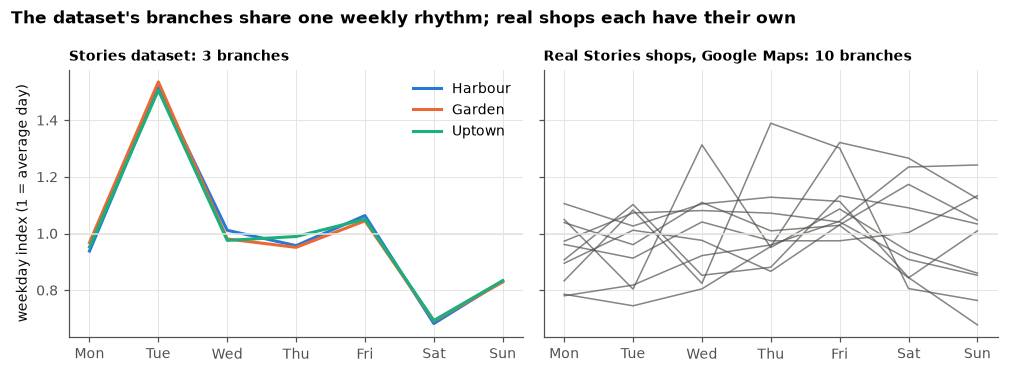

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(9.2, 3.4), sharey=True)
days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
for br in BRANCHES:
    axes[0].plot(range(7), idx["Stories"].loc[br], color=BRANCH_COLORS[br], label=br)
axes[0].set_title("Stories dataset: 3 branches", fontsize=9)
axes[0].legend(loc="upper right")
for b, rowv in idx["Real Stories shops (Google Maps)"].iterrows():
    axes[1].plot(range(7), rowv, color=MUTED, lw=1, alpha=0.7)
axes[1].set_title("Real Stories shops, Google Maps: 10 branches", fontsize=9)
for ax in axes:
    ax.set_xticks(range(7), days); ax.axhline(1, color=GRID, lw=1)
axes[0].set_ylabel("weekday index (1 = average day)")
fig.suptitle("The dataset's branches share one weekly rhythm; real shops each have their own",
             x=0.01, ha="left", fontweight="bold", fontsize=11)
fig.tight_layout(); save(fig, "12_weekday_rhythm_vs_real_shops"); plt.show()

**Observed:** the three Stories branches have practically the same weekday index (they differ by about 0.01), the same hourly shape (no significant difference by branch), and Tuesday raises every hour by the same factor (no significant difference in hourly shape by weekday). The real Stories shops differ from each other far more, and Maven's stores have clearly different hourly shapes.

**Interpretation:** one weekday setting and one hourly setting, applied to every branch, fits the data. The Tuesday spike is part of that shared setting, which is why it appears at every branch, every hour and every week.

## 5. Does every branch grow at the same rate?

In [11]:
month = txn.date.dt.to_period("M")
share = txn.groupby([month, "branch"]).size().unstack()
share = share.div(share.sum(axis=1), axis=0)
growth = {}
for br in BRANCHES:
    w = stories_day[stories_day.store == br].assign(week=lambda d: (d.date - d.date.min()).dt.days // 7)
    w = w.groupby("week").n.agg(["sum", "size"]).query("size == 7")
    growth[br] = np.expm1(np.polyfit(w.index, np.log(w["sum"]), 1)[0])
print("weekly growth by branch:", {k: f"{v:.2%}" for k, v in growth.items()})
share.round(3)

weekly growth by branch: {'Harbour': '2.03%', 'Garden': '1.89%', 'Uptown': '1.71%'}


branch,Garden,Harbour,Uptown
date,,,
2026-01,0.329,0.481,0.190
2026-02,0.337,0.474,0.189
2026-03,0.327,0.479,0.194
2026-04,0.328,0.482,0.190
2026-05,0.330,0.483,0.187
2026-06,0.326,0.490,0.184


**Observed:** weekly growth is 1.7 to 2.0% at the three branches, and each branch's share of transactions moves by about one point at most from January to June.

**Interpretation:** this is the weakest of the checks. Growth is similar but not identical across branches, and chain-wide growth (a new app, a brand campaign) could make real branches grow together. It neither supports nor rules out a single growth setting.

## 6. Basket rules

In [12]:
print("maximum lines in any basket:", txn.lines.max())
print("lines per basket by branch:")
print(pd.crosstab(txn.branch, txn.lines, normalize="index").round(3).to_string())
q = raw.groupby("product").qty.agg(k=lambda s: (s == 2).sum(), n="size")
p_bar = q.k.sum() / q.n.sum()
x2 = ((q.k - q.n * p_bar) ** 2 / (q.n * p_bar * (1 - p_bar))).sum()
print(f"\nquantity-2 rate: {p_bar:.3f} overall; differs by product? p = {1 - chi2.cdf(x2, len(q) - 1):.2f}")
ids = raw.txn.str[4:].astype(int)
print("transaction IDs:", ids.min(), "to", ids.max(), "| distinct:", ids.nunique(),
      "| sorted by date:", raw.assign(i=ids).sort_values("i").date.is_monotonic_increasing)

maximum lines in any basket: 3
lines per basket by branch:
lines        1      2      3
branch                      
Garden   0.533  0.422  0.044
Harbour  0.539  0.417  0.044
Uptown   0.545  0.409  0.046

quantity-2 rate: 0.057 overall; differs by product? p = 0.16
transaction IDs: 1 to 33887 | distinct: 33887 | sorted by date: True


**Observed:** no basket has more than 3 lines, the line-count mix is the same at every branch, the chance that a line has quantity 2 (about 5.7%) does not differ by product, and transaction IDs run 1 to 33,887 without gaps in date order.

**Interpretation:** a hard 3-line limit and one quantity-2 rate for every product, from espresso to chicken bowls, look like generator rules. The gap-free IDs show the file was numbered after it was assembled, consistent with the brief's statement that IDs were replaced.

## 7. Do customers have a home branch?

In [13]:
known = txn.dropna(subset=["cust"])
multi = known.groupby("cust").branch.nunique()
visits = known.groupby("cust").size()
rng = np.random.default_rng(490)
p_br = known.branch.value_counts(normalize=True)
sim = [np.mean([len(set(rng.choice(p_br.index, size=v, p=p_br.values))) > 1 for v in visits]) for _ in range(5)]
print(f"identified customers seen at more than one branch: observed {np.mean(multi > 1):.3f} | if every visit picked a branch at random: {np.mean(sim):.3f}")

identified customers seen at more than one branch: observed 0.938 | if every visit picked a branch at random: 0.940


**Observed:** customers spread their visits across branches exactly as random branch choice predicts (also shown in `01_eda.ipynb`). Real customers normally have a home branch.

## 8. What is *not* uniform

Not everything is identical. The **product and category mix differs significantly by branch**: Garden sells more desserts and Uptown more sandwiches. So the file is not three copies of one branch.

In [14]:
cat = raw.groupby(["branch", "category"]).qty.sum().unstack()
print("category mix differs by branch? p =", f"{chi2_contingency(cat.values)[1]:.1e}")
(cat.div(cat.sum(axis=1), axis=0) * 100).round(1)

category mix differs by branch? p = 1.2e-64


category,Bakery,Breakfast,Cold Coffee,Cold Drinks,Desserts,Hot Coffee,Matcha & Tea,Meals,Sandwiches
branch,,,,,,,,,
Garden,20.9,4.7,13.8,10.1,11.0,15.5,14.6,2.8,6.6
Harbour,22.4,4.5,14.9,10.1,7.7,16.2,15.0,2.7,6.5
Uptown,20.7,4.6,13.8,10.4,7.0,15.8,14.6,2.9,10.2


## 9. Summary and what it means for the team's findings

| Pattern | Looks like a fixed setting? | Evidence | Team finding that depends on it |
|---|---|---|---|
| Branch costs and prices | **Yes, exact formula** | Cost ×1.43 and ×0.96, price ÷1.05 and ×0.96, 45 of 45 products to the cent; a flat extra amount per item fits far worse; same ratio in every category | Garden cost gap ($15,923 / 6 months) and price gap |
| Day-to-day variation | **Yes** | Dispersion ≈ 1.0 (pure chance); Maven ≈ 4.5 | Forecast accuracy; why a simple "same day last week" forecast is hard to beat |
| Weekday and hourly rhythm | **Yes, one shared setting** | Branches differ by ~0.01; real shops differ far more | Tuesday ×1.6 and weak Saturday |
| Growth | Unclear | 1.7 to 2.0% a week by branch; shares move about one point | Growth decomposition |
| Basket structure | **Yes, rules** | Max 3 lines; one quantity-2 rate for all products | Basket and bundle analyses (02 and 06 to 08) |
| Customer branch choice | **Yes, random** | Matches random branch choice | Customer and loyalty findings |
| Product mix by branch | No | Differs significantly | Branch mix effects |

**Conclusion.** The three headline patterns the team explains (Garden's cost and price gap, the Tuesday spike, the weak Saturday) all behave like **fixed settings applied uniformly, with pure-chance noise on top**. The strongest evidence is the cost and price formula: every branch cost and price is an exact multiple of another branch's, to the cent, on all 45 products. Product mix is the main pattern that differs by branch.

**What this changes in the team's recommendations:**
- **Garden cost gap.** It is a formula, so it cannot be recovered by renegotiating ingredients one by one. The finance question becomes precise: *what is the 1.43 in Garden's standard cost, and how much of it is avoidable cash?* If it is an allocation of rent or overhead, the avoidable amount may be zero. `11_garden_profit_outlook.ipynb` sizes both cases.
- **Tuesday and Saturday.** One shared weekday setting at every branch, with no extra day-to-day variation, fits a generator better than a real promotion or event. Real Stories shops show no Tuesday peak. Staffing, targets or offers should not be built on the Tuesday or Saturday pattern until Stories confirms it in raw till data.
- **Offers and forecasts.** Basket rules (3-line maximum, one quantity-2 rate) and pure-chance daily noise limit what any model can learn here, which is consistent with simple forecasts being hard to beat. Offer recommendations (06 to 08) already end in real-store pilots, which is the right protection.

**One question to Stories resolves most of this:** *How was this file produced, and how are branch standard costs and prices calculated?* If the answer is "real tills and a 1.43 cost-allocation rule", the Garden finding becomes an accounting question; if it is "simulated from settings", the Tuesday, Saturday and growth patterns describe the simulator rather than the business.

## 10. Limits of this check

- **Rules exist in real businesses too.** Zone pricing and standard-cost allocation are normal accounting practice, so the price and cost formulas do not prove the data was simulated. They prove the gaps are *formulas*, which is what matters for the decision.
- **No real daily Stories data to compare with.** The "real shops vary more" argument relies on general retail experience, Maven (also fictional) and Google Maps (relative busyness, not sales, from later months).
- **Each test alone is weak; together they are consistent.** The cost, price, weekday and hourly patterns behave like single settings applied everywhere, with pure-chance noise on top. Growth is the exception: it is similar across branches but not clearly a single setting.